# Homes and the School Bus
### NYC affordable housing completions × school-bus breakdowns and delays
**Data Engineering and Visualization — Winter 2026 · Project Milestone 1**

| | |
|---|---|
| Housing & Development dataset | [Affordable Housing Production by Building](https://data.cityofnewyork.us/d/hg8x-zxpr) (`hg8x-zxpr`, catalog H2) |
| Transportation dataset | [Bus Breakdown and Delays](https://data.cityofnewyork.us/d/ez4e-fazm) (`ez4e-fazm`, catalog T5) |
| Integration key | Borough × school year (main) and borough × month (time-series / lag analysis) |
| Website | https://homes-and-the-school-bus.onrender.com/ · Repository: https://github.com/Alielghayesh16006572/homes-and-the-school-bus |

## Team and contributions

| Member (ID) | Research questions | Visualizations | Data cleaning | Integration | Website |
|---|---|---|---|---|---|
| Asser Ehab Khattab (16003477) | RQ2, RQ5 | Two-panel time series, map | Housing: duplicates, borough, dates | Monthly grid + join | Search mode |
| Ali Sherif Elghayesh (16006572) | RQ1, RQ6 | Scatter with fit, grouped bar | Housing: coordinates, unit consistency | School-year aggregation | Map + layout/CSS |
| Ali Ahmed (16001891) | RQ3, RQ7 | Bubble scatter, scatter | Bus: borough mapping, duplicates, students | Post-integration cleaning | Story section + deployment |
| Ahmed Rashad (16004574) | RQ4, RQ8 | Lag heatmap, box plot | Bus: delay-text parsing, outliers | Lagged correlation | Generate Report callback |



## The question

When New York finishes an affordable building, households move in — many with children who must get to
school. The Department of Education's Office of Pupil Transportation runs school buses; HPD finances the housing.
The two agencies plan separately. **Do the boroughs and periods that deliver the most affordable housing also see
more — or longer — school-bus disruptions, and are the lowest-income and youngest riders affected differently?**

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio

sys.path.insert(0, str(Path("src").resolve()))
import pipeline as P      # all cleaning / integration functions (shared with the website)
import figures as F       # one figure function per research question (shared with the website)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7e6e2"})

RAW = Path("data/raw"); PROCESSED = Path("data/processed")
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

# Plotly charts are interactive in Jupyter/Colab, but GitHub cannot display interactive output.
# Adding the png renderer stores a static image next to each chart so it also shows on GitHub.
# This needs the kaleido package (pip install kaleido); without it the charts stay interactive only.
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
except ImportError:
    print("kaleido not installed: Plotly charts will not be visible when the notebook is viewed on GitHub.")

## 1. Loading the data

Both datasets are downloaded through the NYC Open Data SODA API (Listing 2 in the brief). Two details matter:

* The API returns only **1,000 rows** unless `$limit` is set, so `$limit` is set above the size of both datasets.
* `$order=:id` makes the download order stable, so re-running the notebook gives identical results.

**No sampling.** The housing file has a few thousand buildings, and the bus file a few hundred thousand incidents
(exact counts are printed below). Both fit comfortably in memory, so we use the full data rather than a sample —
sampling would only throw away borough-months and make the monthly series noisier. If a Colab session runs out of
memory, set `BUS_WHERE` to a date filter such as `"occurred_on >= '2018-07-01T00:00:00'"` and note it here.

The raw downloads are cached in `data/raw/` so the notebook does not re-download on every run.

In [2]:
BUS_WHERE = None   # e.g. "occurred_on >= '2018-07-01T00:00:00'" if memory is tight

housing_raw = P.load_dataset(P.HOUSING_ID, RAW / "housing_raw.csv")
bus_raw = P.load_dataset(P.BUS_ID, RAW / "bus_raw.csv", where=BUS_WHERE)

print(f"Housing: {housing_raw.shape[0]:,} rows × {housing_raw.shape[1]} columns")
print(f"Bus:     {bus_raw.shape[0]:,} rows × {bus_raw.shape[1]} columns")

Housing: 9,551 rows × 41 columns
Bus:     1,307,362 rows × 21 columns


API column names are lower-case with underscores, while the CSV export uses `Title Case With Spaces`.
`P.normalize_columns` converts both to the same snake_case names (e.g. `1-BR Units` → `br1_units`), so the rest of
the code works whichever way the data was downloaded.

In [3]:
housing_n = P.normalize_columns(housing_raw)
bus_n = P.normalize_columns(bus_raw)
print("Housing columns:", list(housing_n.columns), "\n")
print("Bus columns:", list(bus_n.columns))

Housing columns: ['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'number', 'street', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'nta', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_only', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', 'br1_units', 'br2_units', 'br3_units', 'br4_units', 'br5_units', 'br6_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units'] 

Bus columns: ['school_year', 'busbreakdown_id', 'run_type', 'bus_no', 'route_number', 'reason', 'schools_serviced', 'occurred_on', 'created_on', 'boro', 'bus_company_name', 'how_long_delayed', 'number_of_students_on_the_bus', 'has_co

## 2. Dataset overview and why these two

| | Affordable Housing Production by Building (H2) | Bus Breakdown and Delays (T5) |
|---|---|---|
| Unit of observation | One building in an HPD-financed affordable project | One school-bus breakdown or late run reported by a contractor |
| Columns | 40+ (meets the ≥ 9 requirement) | 21 (meets the ≥ 9 requirement) |
| Geography | Borough, ZIP, community board, census tract, NTA, latitude/longitude | **Borough only** (`Boro`), plus free-text route and school codes |
| Time | Project start, project completion, building completion dates | `Occurred_On` (date-time), `School_Year` |
| Known issues | Confidential projects have no address / building id; buildings still in progress have no completion date; unit counts by income band may not sum to the total | `Boro` includes places outside NYC (Nassau, Westchester, New Jersey…); `How_Long_Delayed` is free text (`"30MINS"`, `"1hr"`, `"20"`…); edited incidents can appear more than once; no service in summer and during the 2020 COVID-19 closure |

**Why this pair.** Housing completions are a direct, dated measure of *new households arriving* in a borough;
school-bus incidents measure how well one part of the transport system is coping. Both cover the same boroughs and
overlapping years (bus data from the 2015-16 school year on), so they can be compared over time inside each
borough.

**How they will be integrated.** The bus data only knows the borough, so finer geography (ZIP, tract,
coordinates) cannot be matched — any join must be at **borough** level. In time, the bus data is organised by
**school year** (July → June), which is also the period over which new students would enrol, so:

* **Main level — borough × school year** (5 boroughs × 11 complete school years): used for the cross-sectional questions
  (RQ1, RQ3, RQ6, RQ7, RQ8).
* **Secondary level — borough × month**: used for the time-series and lag questions (RQ2, RQ4), where a coarser
  level would hide the timing.

Both datasets are *aggregated* to these levels before joining. A row-level join would be meaningless here: there
is no link between a particular building and a particular bus incident, and the two files have very different
numbers of rows.

## 3. Exploratory data analysis
### 3.1 Housing

In [4]:
housing_n.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   project_id                   9551 non-null   int64  
 1   project_name                 9551 non-null   str    
 2   project_start_date           9551 non-null   str    
 3   project_completion_date      7732 non-null   str    
 4   building_id                  7602 non-null   float64
 5   number                       9551 non-null   str    
 6   street                       9551 non-null   str    
 7   borough                      9551 non-null   str    
 8   postcode                     7593 non-null   float64
 9   bbl                          7530 non-null   float64
 10  bin                          7530 non-null   float64
 11  community_board              9551 non-null   str    
 12  council_district             9551 non-null   int64  
 13  census_tract                 

In [5]:
def missing_report(df):
    out = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (100 * df.isna().mean()).round(1),
                        "unique": df.nunique()})
    return out[out["missing"] > 0].sort_values("missing_%", ascending=False)

missing_report(housing_n)

,missing,missing_%,unique
br6_units,9524,99.7,5
br5_units,9478,99.2,11
br4_units,8990,94.1,34
unknown_br_units,8862,92.8,21
other_income_units,8191,85.8,5
moderate_income_units,7857,82.3,104
extremely_low_income_units,7470,78.2,190
middle_income_units,6860,71.8,153
counted_homeownership_units,6821,71.4,137
studio_units,6353,66.5,157


In [6]:
num_cols = ["total_units", "extremely_low_income_units", "very_low_income_units", "low_income_units",
            "br2_units", "br3_units", "latitude", "longitude"]
housing_n[[c for c in num_cols if c in housing_n]].apply(pd.to_numeric, errors="coerce").describe().T

,count,mean,std,min,25%,50%,75%,max
total_units,9551.0,46.653544,92.482144,1.000000,3.000000,12.000000,45.000000,1320.000000
extremely_low_income_units,2081.0,28.286401,44.591950,1.000000,2.000000,8.000000,37.000000,429.000000
very_low_income_units,3400.0,25.495588,49.298987,1.000000,3.000000,7.000000,21.000000,453.000000
low_income_units,5505.0,19.794369,40.718009,1.000000,1.000000,5.000000,19.000000,536.000000
br2_units,6042.0,17.500828,29.515159,1.000000,2.000000,7.000000,18.000000,305.000000
br3_units,3429.0,10.329542,17.156613,1.000000,1.000000,4.000000,11.000000,193.000000
latitude,7593.0,40.747931,0.083191,40.509910,40.677031,40.731651,40.826339,40.906630
longitude,7593.0,-73.919754,0.056561,-74.247685,-73.949682,-73.923641,-73.890763,-73.730624


In [7]:
for col in ["borough", "reporting_construction_type", "extended_affordability_only", "prevailing_wage_status"]:
    print(housing_n[col].value_counts(dropna=False).to_string(), "\n")

borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445 

reporting_construction_type
Preservation        4785
New Construction    4766 

extended_affordability_only
No     8125
Yes    1426 

prevailing_wage_status
Non Prevailing Wage    9392
Prevailing Wage         159 



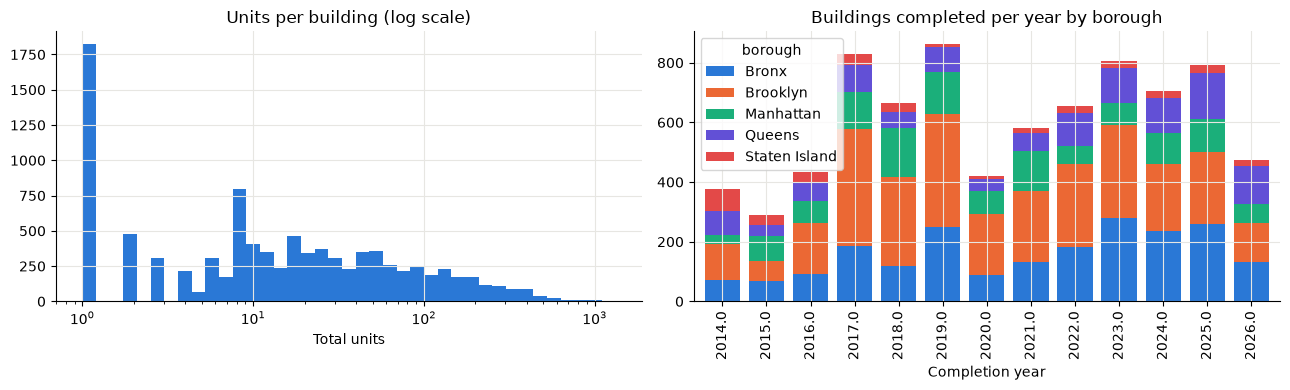

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units = pd.to_numeric(housing_n["total_units"], errors="coerce")
axes[0].hist(units.dropna(), bins=np.logspace(0, np.log10(max(units.max(), 10)), 40), color="#2a78d6")
axes[0].set_xscale("log"); axes[0].set_title("Units per building (log scale)"); axes[0].set_xlabel("Total units")

done = pd.to_datetime(housing_n["building_completion_date"], errors="coerce")
by_year = housing_n.assign(year=done.dt.year).dropna(subset=["year"]).groupby(["year", "borough"]).size().unstack(fill_value=0)
by_year.plot(kind="bar", stacked=True, ax=axes[1], width=0.8, color=["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"])
axes[1].set_title("Buildings completed per year by borough"); axes[1].set_xlabel("Completion year")
plt.tight_layout(); plt.show()

**What we see:** unit counts are heavily right-skewed: the median building has 12 units and 77% have 50 or
fewer, while the largest has 1,320 (mean 46.7), so we use medians and log scales rather than means. 1,666
buildings (17%) have no building completion date, almost all because they are still under construction, and
1,958 (20.5%) have no coordinates; 1,949 of those are confidential projects, which also have no `building_id`.
Unit counts by income band and bedroom size are often blank, which means 0 units in that category.

### 3.2 Bus breakdowns and delays

In [9]:
bus_n.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1307362 entries, 0 to 1307361
Data columns (total 21 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   school_year                      1307361 non-null  str    
 1   busbreakdown_id                  1307362 non-null  int64  
 2   run_type                         1307330 non-null  str    
 3   bus_no                           1307301 non-null  str    
 4   route_number                     1307227 non-null  str    
 5   reason                           1163058 non-null  str    
 6   schools_serviced                 1303733 non-null  str    
 7   occurred_on                      1307361 non-null  str    
 8   created_on                       1307361 non-null  str    
 9   boro                             1283283 non-null  str    
 10  bus_company_name                 1303870 non-null  str    
 11  how_long_delayed                 1126768 non-null  str    
 1

In [10]:
missing_report(bus_n)

,missing,missing_%,unique
incident_number,1294844,99.0,9316
how_long_delayed,180594,13.8,5584
reason,144304,11.0,10
boro,24079,1.8,12
bus_company_name,3492,0.3,1013
schools_serviced,3629,0.3,63987
school_year,1,0.0,32
occurred_on,1,0.0,583125
route_number,135,0.0,23253
run_type,32,0.0,10


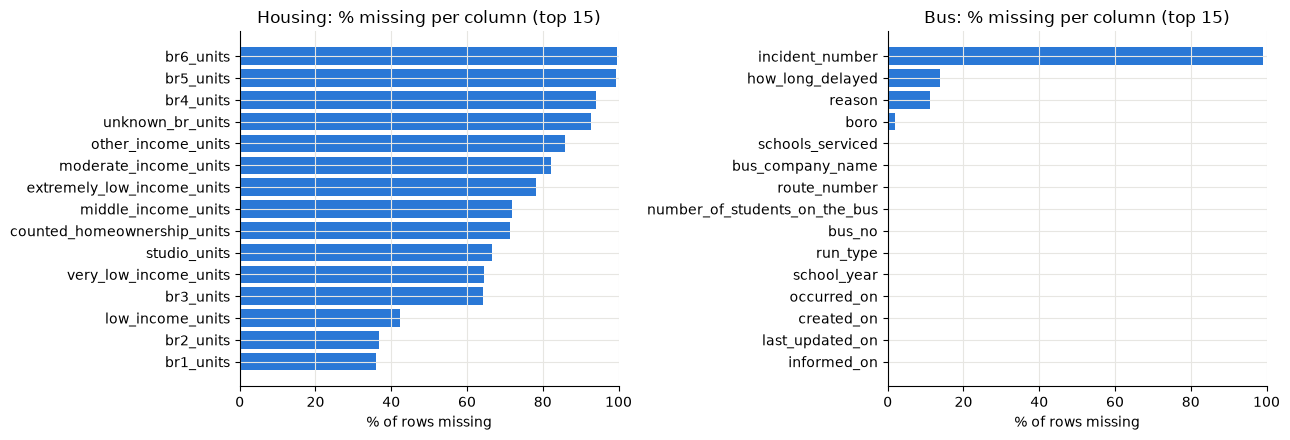

In [11]:
# Missing values at a glance: the 15 columns with the most gaps in each dataset.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, df) in zip(axes, [("Housing", housing_n), ("Bus", bus_n)]):
    share = (100 * df.isna().mean()).sort_values(ascending=False).head(15)
    share = share[share > 0][::-1]          # largest at the top of the bar chart
    ax.barh(share.index, share.values, color="#2a78d6")
    ax.set_xlim(0, 100); ax.set_xlabel("% of rows missing")
    ax.set_title(f"{name}: % missing per column (top 15)")
plt.tight_layout(); plt.show()

In [12]:
for col in ["boro", "breakdown_or_running_late", "reason", "school_age_or_prek", "run_type"]:
    print(bus_n[col].value_counts(dropna=False).head(15).to_string(), "\n")

boro
Brooklyn           318894
Bronx              297249
Manhattan          257489
Queens             252528
Staten Island       62835
Nassau County       44301
Westchester         33145
NaN                 24079
New Jersey           6189
Connecticut          4445
All Boroughs         3422
Rockland County      2560
Suffolk               226 

breakdown_or_running_late
Running Late    1146061
Breakdown        161301 

reason
Heavy Traffic                  690926
Other                          194277
NaN                            144304
Mechanical Problem             100033
Problem Run                     42532
Won`t Start                     38145
Weather Conditions              35665
Flat Tire                       22693
Late return from Field Trip     17424
Delayed by School               11386
Accident                         9977 

school_age_or_prek
School-Age    1187803
Pre-K          119559 

run_type
Special Ed AM Run          795488
Special Ed PM Run          172585
General Ed

In [13]:
print("Most frequent raw How_Long_Delayed values:")
print(bus_n["how_long_delayed"].value_counts(dropna=False).head(25).to_string())
print("\nDistinct raw values:", bus_n["how_long_delayed"].nunique())

Most frequent raw How_Long_Delayed values:
how_long_delayed
16-30 Min     218814
31-45 Min     180723
NaN           180594
61-90 Min     101775
46-60 Min     101286
0-15 Min       76733
20 min         14747
30 min         13248
30MINS         12149
30 MINS        11515
15 min         10403
20 mins        10119
20 MINS        10018
20 MIN          9945
30 mins         9883
30 MIN          9847
15 mins         9654
20              8737
20mins          7036
30 MINS.        6867
30 minutes      6254
30mins          5976
15              5827
15 MINS         5608
20min           5496

Distinct raw values: 5584


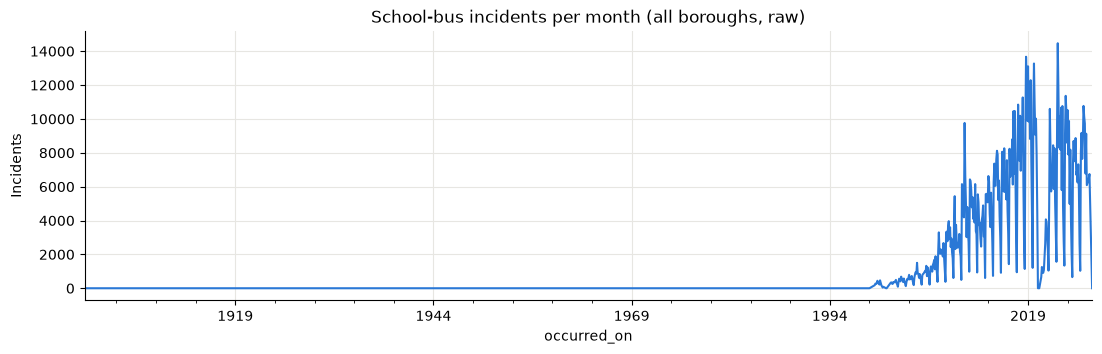

count    1.307291e+06
mean     3.511698e+00
std      7.458282e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.000000e+00
max      3.600500e+04
Name: number_of_students_on_the_bus, dtype: float64


In [14]:
occ = pd.to_datetime(bus_n["occurred_on"], errors="coerce")
monthly_counts = occ.dt.to_period("M").value_counts().sort_index()
ax = monthly_counts.plot(figsize=(13, 3.5), color="#2a78d6")
ax.set_title("School-bus incidents per month (all boroughs, raw)"); ax.set_ylabel("Incidents")
plt.show()

students = pd.to_numeric(bus_n["number_of_students_on_the_bus"], errors="coerce")
print(students.describe())

**What we see:** `Boro` contains values outside the five boroughs; `How_Long_Delayed` is free text with many
spellings of the same duration; incidents drop to almost zero every July–August and from March 2020 (school
closures), so those months are *no service*, not *no problems*; and the student count has impossible maxima.

## 4. Pre-integration cleaning

All steps live in `src/pipeline.py` (`clean_housing`, `clean_bus`) so the website uses exactly the same logic.
Every step is recorded in a `CleaningLog`, shown at the end of this section. Below, each decision is justified and
the evidence for it is shown before the function is run.

### 4.1 Housing — decisions

| Issue | Decision | Why |
|---|---|---|
| Exact duplicate rows; same `(project_id, building_id)` twice | Drop, keep the last | The same building would otherwise be counted twice. Confidential rows have no `building_id`, so they are only de-duplicated when the whole row is identical. |
| Borough missing / unrecognised | **Drop** | Borough is the join key; such a row cannot be placed. Very few rows. |
| `building_completion_date` missing but `project_completion_date` present | **Impute** from the project date | Buildings in a project are delivered together; this keeps real completions in the analysis. Flagged in `completion_imputed`. |
| No completion date at all | **Drop from the integrated analysis** | The building is not finished, so it has no month in which households arrived. Imputing a date would invent an event. |
| Missing unit count in an income/bedroom category | **Fill with 0** | A blank category in this file means "no units of that type". |
| Coordinates outside NYC's bounding box | **Blank** them (keep the row) | They are entry errors; the row still has a valid borough, so it stays in every borough-level result and is only left off the map. |
| Completion before start, completion in the future, `total_units ≤ 0` | **Drop** | Logically impossible values. |
| Income bands not adding up to `total_units` | **Flag** (`units_mismatch`), keep | We cannot tell which number is wrong; totals are still used. |
| Very large buildings (IQR outliers in `total_units`) | **Flag** (`units_outlier_iqr`), keep | They are real towers, not errors. Dropping them would remove exactly the developments that bring the most households. |
| Borough spelling, dates, ZIP codes, category text | Standardise | Upper-case official borough names, real datetimes, 5-digit ZIP strings, title-cased categories. |

In [15]:
dup_exact = housing_n.duplicated().sum()
dup_key = housing_n[housing_n["building_id"].notna()].duplicated(["project_id", "building_id"]).sum()
print(f"Exact duplicate rows: {dup_exact:,}   duplicate (project_id, building_id): {dup_key:,}")

units = pd.to_numeric(housing_n["total_units"], errors="coerce")
lo, hi = P.iqr_bounds(units.dropna())
print(f"total_units IQR fences: [{lo:.0f}, {hi:.0f}] -> {(units > hi).sum():,} buildings above the upper fence "
      f"(max = {units.max():,.0f} units). These are kept and flagged.")

Exact duplicate rows: 0   duplicate (project_id, building_id): 0
total_units IQR fences: [-60, 108] -> 1,171 buildings above the upper fence (max = 1,320 units). These are kept and flagged.


### 4.2 Bus — decisions

| Issue | Decision | Why |
|---|---|---|
| Exact duplicates; same `busbreakdown_id` several times | Drop; keep the **latest** `last_updated_on` | Contractors edit incidents; the last edit is the final record. |
| `Boro` outside NYC or missing | **Drop** | No NYC housing counterpart; these incidents cannot be integrated. |
| `occurred_on` missing, before July 2015 or in the future | **Drop** | No usable date to aggregate on. |
| `school_year` disagreeing with `occurred_on` | **Recompute** from the date | The date is the primary field; the label is derived from it. |
| `How_Long_Delayed` free text | **Parse** to `delay_minutes` (`P.parse_delay_minutes`) | Handles `"25 minutes"`, `"30MINS"`, `"20"`, `"1hr"`, `"1:30"`, `"45-60 min"` (mid-point) … |
| Delay unparseable, ≤ 0 or > 240 min | **Set to NaN — do not impute** | A filled-in delay would be invented data and would pull every median toward the fill value. Counts of incidents still use these rows. |
| Students on bus > 90 | **Set to NaN** | Domain rule: the largest NYC school buses seat roughly 66–90 pupils. |
| Yes/No columns, category text, company names | Standardise | Booleans; title case; collapsed whitespace. |

In [16]:
demo = bus_n["how_long_delayed"].dropna().drop_duplicates().sample(min(15, bus_n["how_long_delayed"].nunique()), random_state=0)
pd.DataFrame({"raw text": demo, "parsed minutes": demo.map(P.parse_delay_minutes)})

,raw text,parsed minutes
141397,45MINUTES,45.0
428037,1-2 hours,90.0
494899,145 mins,145.0
160718,35 min+,35.0
423139,9839,9839.0
255009,15 AM,15.0
224894,5 to45mins,25.0
107473,40MIN,40.0
129487,3O MINUTES,3.0
150714,50,50.0


In [17]:
parsed = bus_n["how_long_delayed"].map(P.parse_delay_minutes)
lo, hi = P.iqr_bounds(parsed.dropna())
print(f"Delay (min) IQR fences: [{lo:.0f}, {hi:.0f}]")
print(f"Above IQR fence: {(parsed > hi).sum():,}   above domain cap of {P.MAX_PLAUSIBLE_DELAY_MIN} min: "
      f"{(parsed > P.MAX_PLAUSIBLE_DELAY_MIN).sum():,}   unparseable: {parsed.isna().sum():,}")

Delay (min) IQR fences: [-7, 65]
Above IQR fence: 108,182   above domain cap of 240 min: 614   unparseable: 182,662


**Why a domain cap instead of the IQR fence for delays?** The IQR fence on delay minutes is low (delays cluster
around 15–45 min), so it would discard genuine one- and two-hour delays — the very cases parents care about. We
therefore *report* the IQR fence but cut only values that cannot be a delay (≤ 0, or more than 4 hours, which is a
cancelled run or a typo). The same reasoning applies to students on the bus, capped by vehicle capacity.

In [18]:
log = P.CleaningLog()
housing = P.clean_housing(housing_raw, log)
bus = P.clean_bus(bus_raw, log)
log.to_frame()

,dataset,step,rows_before,rows_after,rows_removed,note
0,housing,drop exact duplicates,9551,9551,0,
1,housing,"drop duplicate (project_id, building_id)",9551,9551,0,"confidential rows have no building_id, so they..."
2,housing,drop rows with missing/invalid borough,9551,9551,0,
3,housing,impute 13 building dates from project date,9551,9551,0,
4,housing,drop buildings still in progress (no completio...,9551,7898,1653,
5,housing,blank 1880 coordinates outside NYC / missing,7898,7898,0,
6,housing,drop completion date earlier than start date,7898,7877,21,
7,housing,drop completion dates in the future,7877,7877,0,
8,housing,drop buildings with total_units <= 0,7877,7877,0,
9,bus,drop exact duplicates,1307362,1307362,0,


All pre-integration checks passed.


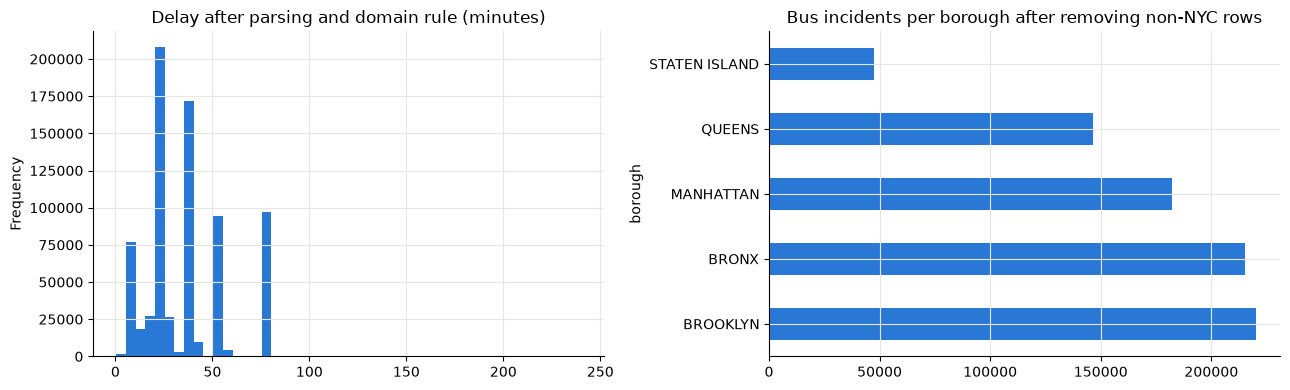

In [19]:
# Validation: the cleaned data no longer has the problems found in EDA.
assert housing["borough"].isin(P.BOROUGHS).all() and bus["borough"].isin(P.BOROUGHS).all()
assert housing.duplicated().sum() == 0 and bus["busbreakdown_id"].is_unique
assert housing["building_completion_date"].notna().all() and bus["occurred_on"].notna().all()
assert (bus["delay_minutes"].dropna().between(0, P.MAX_PLAUSIBLE_DELAY_MIN)).all()
assert (bus["number_of_students_on_the_bus"].dropna() <= P.MAX_STUDENTS_ON_BUS).all()
print("All pre-integration checks passed.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bus["delay_minutes"].plot(kind="hist", bins=48, ax=axes[0], color="#2a78d6")
axes[0].set_title("Delay after parsing and domain rule (minutes)")
bus["borough"].value_counts().plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].set_title("Bus incidents per borough after removing non-NYC rows")
plt.tight_layout(); plt.show()

**Validating the cleaning visually.** The checks above confirm each rule was applied; the charts below show
how much each step removed, what happened to the delay text once parsed, and which raw `Boro` values were
kept or dropped.

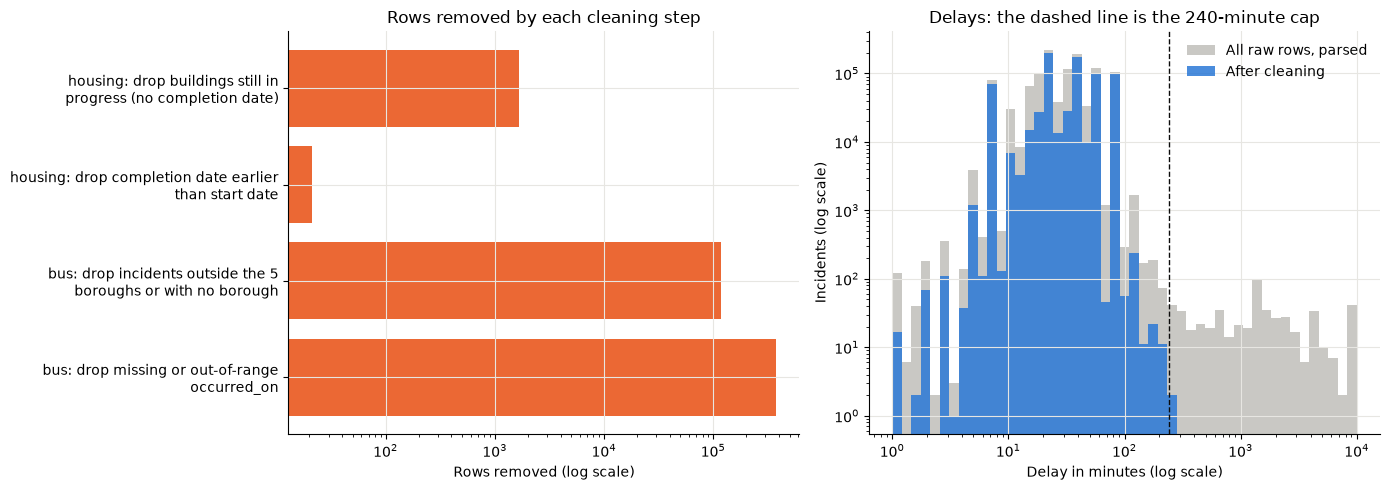

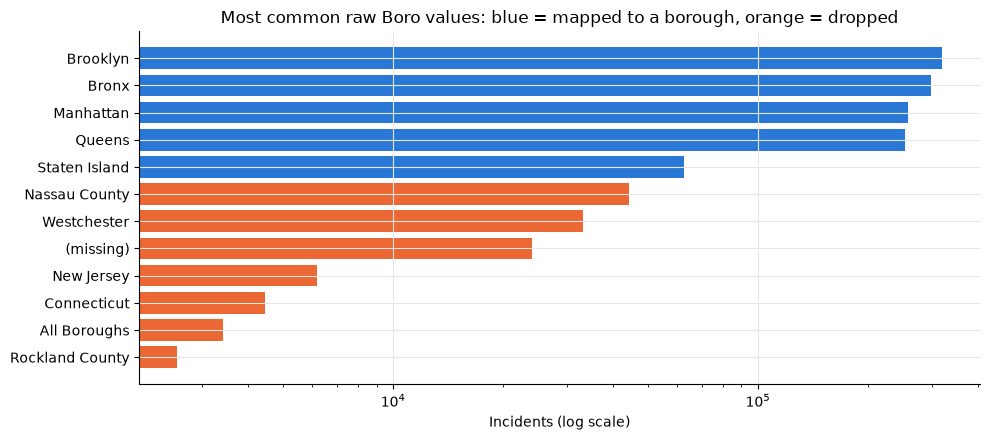

In [20]:
import textwrap

steps = log.to_frame()
removed = steps[steps["rows_removed"] > 0]
labels = (removed["dataset"] + ": " + removed["step"]).map(lambda s: textwrap.fill(s, 38))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(labels[::-1], removed["rows_removed"][::-1], color="#eb6834")
axes[0].set_xscale("log"); axes[0].set_xlabel("Rows removed (log scale)")
axes[0].set_title("Rows removed by each cleaning step")

# Parsed delay of every raw row vs. the cleaned column: the domain rule cuts only the far right tail.
raw_delay = bus_n["how_long_delayed"].map(P.parse_delay_minutes)
bins = np.logspace(0, 4, 50)
axes[1].hist(raw_delay[raw_delay > 0], bins=bins, color="#c9c8c4", label="All raw rows, parsed")
axes[1].hist(bus["delay_minutes"].dropna(), bins=bins, color="#2a78d6", alpha=0.85, label="After cleaning")
axes[1].axvline(P.MAX_PLAUSIBLE_DELAY_MIN, color="#0b0b0b", ls="--", lw=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")   # log y so the few capped delays stay visible
axes[1].set_xlabel("Delay in minutes (log scale)"); axes[1].set_ylabel("Incidents (log scale)")
axes[1].set_title(f"Delays: the dashed line is the {P.MAX_PLAUSIBLE_DELAY_MIN}-minute cap")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

# Raw borough spellings: which are mapped to one of the five boroughs and which are dropped.
raw_boro = bus_n["boro"].astype("string").str.strip().fillna("(missing)")
counts = raw_boro.value_counts().head(12)[::-1]
kept = P.standardize_borough(pd.Series(counts.index)).notna().to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(counts.index, counts.values, color=np.where(kept, "#2a78d6", "#eb6834"))
ax.set_xscale("log"); ax.set_xlabel("Incidents (log scale)")
ax.set_title("Most common raw Boro values: blue = mapped to a borough, orange = dropped")
plt.tight_layout(); plt.show()

## 5. Integration

**Join key and granularity.** Alternatives considered:

* *ZIP code / census tract / coordinates* — the bus file has none of them, so impossible.
* *School or route* — the bus file names schools by code, but the housing file has no link to schools; matching
  buildings to schools would need a third dataset (school zones), which is outside the brief.
* *Borough × calendar year* — workable, but splits each school year across two calendar years.
* **Borough × school year** (chosen as the main level) — matches how the bus system is organised and when
  households' children would enrol.
* **Borough × month** (chosen for timing questions) — fine enough to see seasonality, the 2020 closure and lags.

**Aggregation.** Housing → buildings, units, deeply affordable units (extremely + very low income), family-sized
units (2+ bedrooms), new-construction vs. preservation units per borough-period. Bus → incidents, breakdowns,
heavy-traffic incidents, Pre-K incidents, median delay, average students per borough-period.

**Join type.** A complete borough × period *grid* is built first and both aggregates are left-joined onto it. An
inner join would silently drop borough-months with zero completions; an outer join without the grid could still
miss periods present in neither table. The window is restricted to the period both datasets cover. At school-year level only **complete** school years are kept: the newest school year (2026-27) had only a few months of data, and a partial year is low on both housing and bus counts, which inflated every correlation when it was included.

In [21]:
span = P.common_span(housing, bus)
merged_monthly = P.integrate(housing, bus, "month", span)
merged_yearly = P.integrate(housing, bus, "school_year", span)
print("Monthly:", merged_monthly.shape, "  span:", merged_monthly["month"].min().date(), "->", merged_monthly["month"].max().date())
print("Yearly: ", merged_yearly.shape, "  school years:", merged_yearly["school_year"].min(), "->", merged_yearly["school_year"].max())
merged_monthly.head()

Monthly: (670, 19)   span: 2015-07-01 -> 2026-08-01
Yearly:  (55, 17)   school years: 2015-2016 -> 2025-2026


,borough,month,school_year,buildings_completed,units_completed,deeply_affordable_units,family_units,new_construction_units,preservation_units,incidents,breakdowns,heavy_traffic_incidents,prek_incidents,median_delay_min,delay_obs,avg_students,running_late,heavy_traffic_share,school_year_bus
0,BRONX,2015-07-01,2015-2016,4.0,6.0,0.0,0.0,2.0,4.0,603.0,132,271,266,20.0,468.0,4.461028,471,0.44942,2015-2016
1,BRONX,2015-08-01,2015-2016,1.0,1.0,1.0,1.0,1.0,0.0,175.0,31,66,97,20.0,139.0,2.148571,144,0.377143,2015-2016
2,BRONX,2015-09-01,2015-2016,NaN,NaN,NaN,NaN,NaN,NaN,1579.0,142,970,724,15.0,1407.0,5.060317,1437,0.614313,2015-2016
3,BRONX,2015-10-01,2015-2016,3.0,140.0,0.0,81.0,55.0,85.0,2442.0,216,1502,1183,20.0,2162.0,4.520885,2226,0.61507,2015-2016
4,BRONX,2015-11-01,2015-2016,2.0,2.0,1.0,1.0,2.0,0.0,1594.0,208,902,713,20.0,1327.0,4.021330,1386,0.565872,2015-2016


## 6. Post-integration cleaning

The join itself creates three kinds of problems, each inspected below and then fixed by
`P.post_integration_clean`:

1. **New missing values.** Housing NaN = no building completed that period → **0**. Bus NaN in a month when the
   whole city has (almost) no incidents = **no school-bus service** (summer, COVID closure) → kept as **NaN** and
   flagged `school_in_session = False`, so these months are excluded from averages and correlations rather than
   counted as perfect months. A borough with no incidents in an in-session month gets 0.
2. **Redundant / conflicting columns.** The monthly join carries two `school_year` columns (one derived from the
   grid month, one from the bus file). We check they agree, then keep the date-derived one. We also add
   `other_construction_units` so that construction-type units add up to the total.
3. **Data-type mismatches.** Left joins turn integer counts into floats (because of NaN); they are cast back to
   nullable integers (`Int64`). `month` is forced to datetime and `borough`/`school_year` to string so both
   aggregates use identical key types.

In [22]:
print("Missing values created by the join (monthly):")
print(merged_monthly.isna().sum()[lambda s: s > 0].to_string())
print("\nConflicting columns:", [c for c in merged_monthly.columns if c.endswith("_bus")])
print("\nDtypes before:", merged_monthly[["units_completed", "incidents", "breakdowns"]].dtypes.to_dict())

Missing values created by the join (monthly):
buildings_completed        37
units_completed            37
deeply_affordable_units    37
family_units               37
new_construction_units     37
preservation_units         37
incidents                  33
breakdowns                 33
heavy_traffic_incidents    33
prek_incidents             33
median_delay_min           34
delay_obs                  33
avg_students               33
running_late               33
heavy_traffic_share        33
school_year_bus            33

Conflicting columns: ['school_year_bus']

Dtypes before: {'units_completed': dtype('float64'), 'incidents': dtype('float64'), 'breakdowns': Int64Dtype()}


In [23]:
post_log = P.CleaningLog()
monthly = P.post_integration_clean(merged_monthly, "month", post_log)
yearly = P.post_integration_clean(merged_yearly, "school_year", post_log)
display(post_log.to_frame())

print("Dtypes after:", monthly[["units_completed", "incidents", "breakdowns"]].dtypes.to_dict())
print("Remaining NaN in housing counts:", int(monthly[P.HOUSING_COUNT_COLS].isna().sum().sum()))
print("Months flagged without school service:", int((~monthly["school_in_session"]).sum()))

assert not monthly.duplicated(["borough", "month"]).any() and not yearly.duplicated(["borough", "school_year"]).any()
assert monthly[P.HOUSING_COUNT_COLS].notna().all().all()
assert monthly.loc[monthly["school_in_session"], "incidents"].notna().all()
print("All post-integration checks passed.")
yearly.head(10)

,dataset,step,rows_before,rows_after,rows_removed,note
0,integrated,school_year columns disagree on 0 rows -> keep...,670,670,0,
1,integrated,flag 35 borough-months with no school bus service,670,670,0,"bus metrics left NaN, excluded from correlations"
2,integrated,"drop duplicate (borough, period) keys",670,670,0,
3,integrated,"drop duplicate (borough, period) keys",55,55,0,


Dtypes after: {'units_completed': Int64Dtype(), 'incidents': Int64Dtype(), 'breakdowns': Int64Dtype()}
Remaining NaN in housing counts: 0
Months flagged without school service: 35
All post-integration checks passed.


,borough,school_year,buildings_completed,units_completed,deeply_affordable_units,family_units,new_construction_units,preservation_units,incidents,breakdowns,heavy_traffic_incidents,prek_incidents,median_delay_min,delay_obs,avg_students,running_late,heavy_traffic_share,other_construction_units
0,BRONX,2015-2016,80,2028,1161,1128,211,1817,17898,1909,10536,7118,20.0,15620,3.850229,15989,0.588669,0
1,BRONX,2016-2017,103,4875,2185,2239,1270,3605,23389,3367,15814,8910,20.0,19613,3.705135,20022,0.67613,0
2,BRONX,2017-2018,179,7608,3442,3634,1940,5668,20354,3037,13068,7001,23.0,17306,3.288924,17317,0.642036,0
3,BRONX,2018-2019,244,8576,2741,3904,4700,3876,28389,3181,19006,10582,38.0,25208,2.699013,25208,0.669485,0
4,BRONX,2019-2020,107,5124,1326,2468,2632,2492,16922,2053,10793,5566,23.0,14869,3.311007,14869,0.637809,0
5,BRONX,2020-2021,116,5986,2970,2660,3674,2312,4332,321,2664,835,23.0,4011,0.832140,4011,0.614958,0
6,BRONX,2021-2022,154,13392,8058,6934,3912,9480,17471,970,11011,4021,23.0,16501,2.898923,16501,0.630244,0
7,BRONX,2022-2023,258,16263,8164,7314,5213,11050,19188,1281,12828,3397,23.0,17907,2.823453,17907,0.668543,0
8,BRONX,2023-2024,247,12488,4567,4605,6815,5673,21748,1038,15234,4542,23.0,20710,3.132542,20710,0.700478,0
9,BRONX,2024-2025,241,9867,2722,2795,7638,2229,20584,878,15616,4049,23.0,19706,2.659003,19706,0.758647,0


### Save the processed data for the website

The website re-aggregates from the cleaned *row-level* tables (so filters like "Breakdown only" or
"New Construction only" can be applied before aggregation). Only the columns the website needs are saved,
compressed, so the repository stays small.

In [24]:
HOUSING_APP_COLS = ["project_id", "project_name", "building_id", "borough", "postcode", "latitude", "longitude",
                    "building_completion_date", "completion_month", "school_year", "reporting_construction_type",
                    "total_units", "extremely_low_income_units", "very_low_income_units", "deeply_affordable_units",
                    "family_units"]
BUS_APP_COLS = ["busbreakdown_id", "borough", "school_year", "occurred_on", "month", "reason",
                "breakdown_or_running_late", "school_age_or_prek", "delay_minutes",
                "number_of_students_on_the_bus", "is_breakdown", "is_heavy_traffic", "is_prek"]

housing[HOUSING_APP_COLS].to_csv(PROCESSED / "housing_clean.csv.gz", index=False)
bus[BUS_APP_COLS].to_csv(PROCESSED / "bus_clean.csv.gz", index=False)
monthly.to_csv(PROCESSED / "integrated_borough_month.csv", index=False)
yearly.to_csv(PROCESSED / "integrated_borough_school_year.csv", index=False)
for f in sorted(PROCESSED.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:6.2f} MB")

.gitkeep                                   0.00 MB
bus_clean.csv.gz                           6.44 MB
housing_clean.csv.gz                       0.19 MB
integrated_borough_month.csv               0.09 MB
integrated_borough_school_year.csv         0.01 MB


## 7. Research questions

Each member contributes two questions, each answered by one chart. The charts are produced by `src/figures.py` —
the same functions the website calls — so what you see here is what the website shows with no filters applied.

> **Interpretation cells:** the *Answer* cell under each chart must be written by the member after running the
> notebook on the real data. Describe what the chart shows, give the number (r, share, median), and say how
> confident you are. Do not claim causation.

### RQ1 (Ali Sherif Elghayesh)
**Question:** Do borough-years that delivered more affordable units also log more school-bus incidents?

**Chart:** Scatter of units completed vs. incidents, one point per borough × school year, with a pooled linear fit.

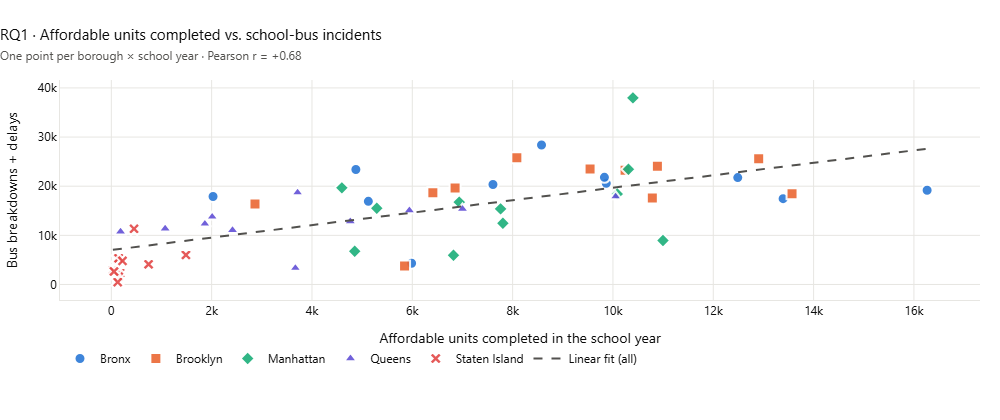

In [25]:
F.rq1_units_vs_incidents(yearly).show()

In [26]:
r_units = P.ols_line(yearly['units_completed'], yearly['incidents'])[2]
print(f'Pearson r (all borough-years): {r_units:+.2f}')
for b, g in yearly.groupby('borough'):
    print(f'  within {b:14s} r = {P.ols_line(g["units_completed"], g["incidents"])[2]:+.2f}')

Pearson r (all borough-years): +0.68
  within BRONX          r = +0.18
  within BROOKLYN       r = +0.48
  within MANHATTAN      r = +0.40
  within QUEENS         r = +0.49
  within STATEN ISLAND  r = +0.38


**Answer (Ali Sherif Elghayesh):** Across 55 complete borough-school-years (2015-16 to 2025-26), affordable units completed and school-bus incidents are positively correlated (r = +0.68). Part of this is borough size: larger boroughs have both more housing and more bus service. The link remains within each borough, but it is weaker (r = +0.18 in the Bronx up to +0.49 in Queens), so a borough's higher-completion years tended to also be higher-incident years. Each within-borough value rests on only 11 school years, and both series dip in 2020-21 (school closures), which contributes to the correlation. This is a modest association, not evidence that new housing causes bus disruptions.

**Caveat:** Pooling boroughs mixes *between*-borough size differences with *within*-borough change; the per-borough r values printed above separate the two.

### RQ2 (Asser Ehab Khattab)
**Question:** Over time, does the 12-month pipeline of new affordable units move with monthly school-bus incidents in each borough?

**Chart:** Two panels on a shared time axis (rolling 12-month completions; monthly incidents with gaps where there is no service). Two panels instead of a dual-axis chart, so neither scale is distorted.

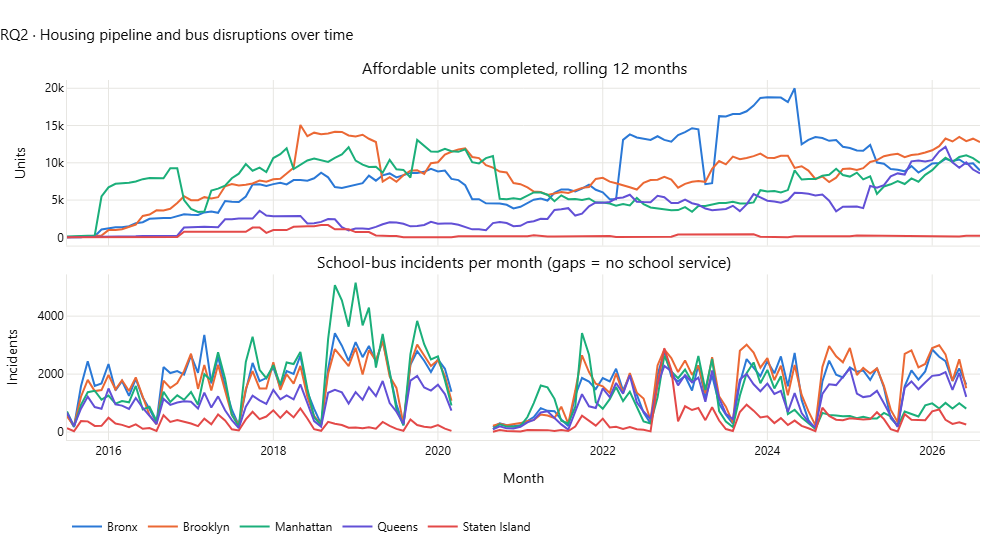

In [27]:
F.rq2_timeline(monthly).show()

**Answer (Asser Ehab Khattab):** The incident panel is dominated by the school calendar: incidents peak during the school year, drop to almost nothing every July-August, and stop from March 2020 until schools reopened in 2020-21. The biggest peak is Manhattan in the 2018-19 school year (its worst months reach about 5,000 incidents). The housing pipeline follows a different rhythm. For example, the Bronx's rolling 12-month completions climbed to about 20,000 units in 2023-24 with no matching rise in its monthly incidents. Over time the two series do not visibly move together; RQ4 tests the timing formally.

**Caveat:** Look for whether peaks in the housing panel are followed by rises in the bus panel, and how the 2020 closure breaks the series.

### RQ3 (Ali Ahmed)
**Question:** Where a larger share of new units is reserved for extremely and very low-income households, are school-bus delays longer?

**Chart:** Bubble scatter: x = % of units that are extremely/very low income, y = median reported delay, bubble size = units completed.

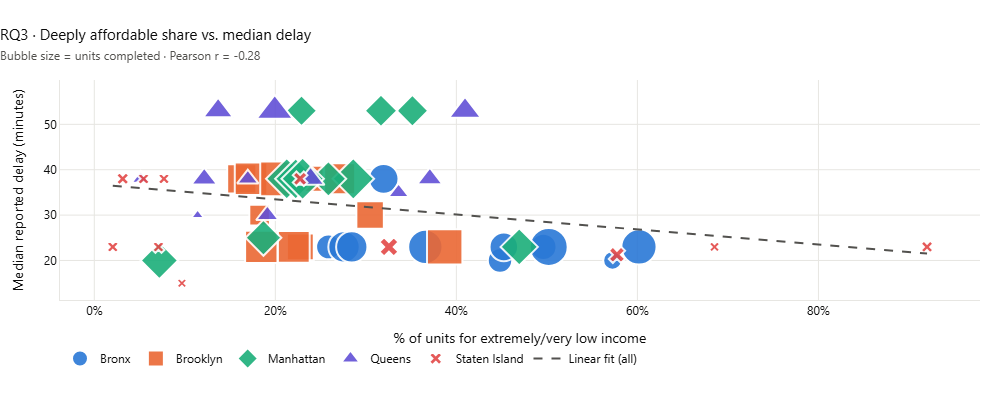

In [28]:
F.rq3_deep_affordability_vs_delay(yearly).show()

**Answer (Ali Ahmed):** Across borough-years, a higher share of units for extremely and very low-income households goes with slightly *shorter* median delays (r = -0.28), the opposite of the hypothesis. Within boroughs the direction is not consistent (from -0.38 in Staten Island to +0.25 in Manhattan). Median delays differ mainly by borough: typically 23 min in the Bronx and Staten Island, 30 in Brooklyn and 38 in Manhattan and Queens. The recurring values 23, 38 and 53 suggest delays are mostly entered as ranges (such as 16-30 minutes) and parsed to their midpoints, which limits precision. There is no evidence that deeply affordable housing is associated with longer delays.

**Caveat:** Median delays are reported in coarse steps (15, 20, 30 min…), so small differences may be reporting artefacts.

### RQ4 (Ahmed Rashad)
**Question:** Do housing completions precede school-bus incidents, and by how many months?

**Chart:** Heatmap of Pearson r between completions shifted by 0–12 months and monthly incidents, per borough (diverging scale, grey = no correlation).

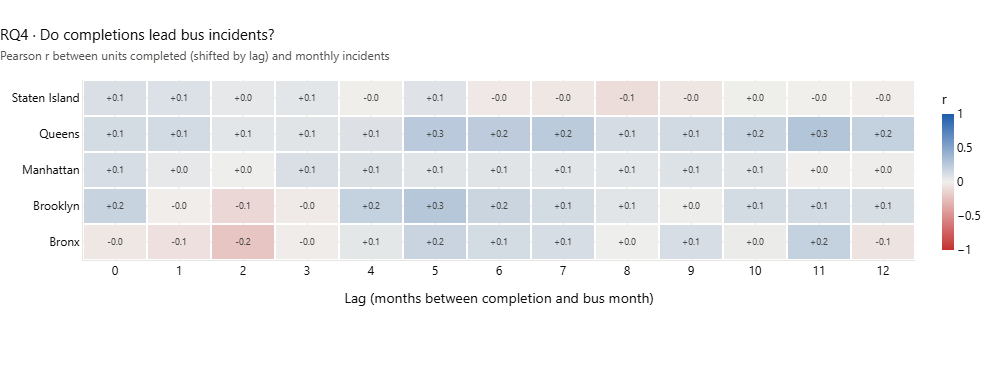

In [29]:
F.rq4_lag_heatmap(monthly).show()

In [30]:
lags = P.lagged_correlations(monthly)
lags.pivot(index='borough', columns='lag_months', values='r').round(2)

lag_months,0,1,2,3,4,5,6,7,8,9,10,11,12
borough,,,,,,,,,,,,,
BRONX,-0.04,-0.08,-0.22,-0.02,0.06,0.18,0.14,0.12,0.01,0.12,0.03,0.21,-0.06
BROOKLYN,0.19,-0.01,-0.12,-0.03,0.21,0.27,0.18,0.14,0.07,0.02,0.14,0.14,0.12
MANHATTAN,0.12,0.05,0.01,0.11,0.10,0.07,0.07,0.07,0.06,0.09,0.07,0.00,0.01
QUEENS,0.14,0.14,0.06,0.07,0.09,0.26,0.24,0.25,0.13,0.15,0.19,0.29,0.21
STATEN ISLAND,0.11,0.10,0.05,0.06,-0.00,0.08,-0.03,-0.04,-0.10,-0.05,0.01,-0.00,-0.01


**Answer (Ahmed Rashad):** No reliable lead was found. For lags of 0 to 12 months, the correlation between monthly completions and monthly incidents stays between -0.22 and +0.29 in every borough. Averaged across boroughs, the strongest lag is 5 months (mean r = +0.17); only Queens shows a fairly steady positive pattern (+0.24 to +0.29 at lags 5-11). Monthly completions are lumpy and incidents follow the school calendar, so a shared seasonal rhythm alone could produce weak correlations like these. Completions do not reliably precede bus problems at any lag.

**Caveat:** Both series share the school-year rhythm; a positive lag correlation can come from that common seasonality alone.

### RQ5 (Asser Ehab Khattab)
**Question:** Is new affordable housing concentrated in the same boroughs where school-bus disruptions concentrate?

**Chart:** Map: each building as a dot (size = units, colour = new construction vs. preservation) over grey borough bubbles sized by total bus incidents.

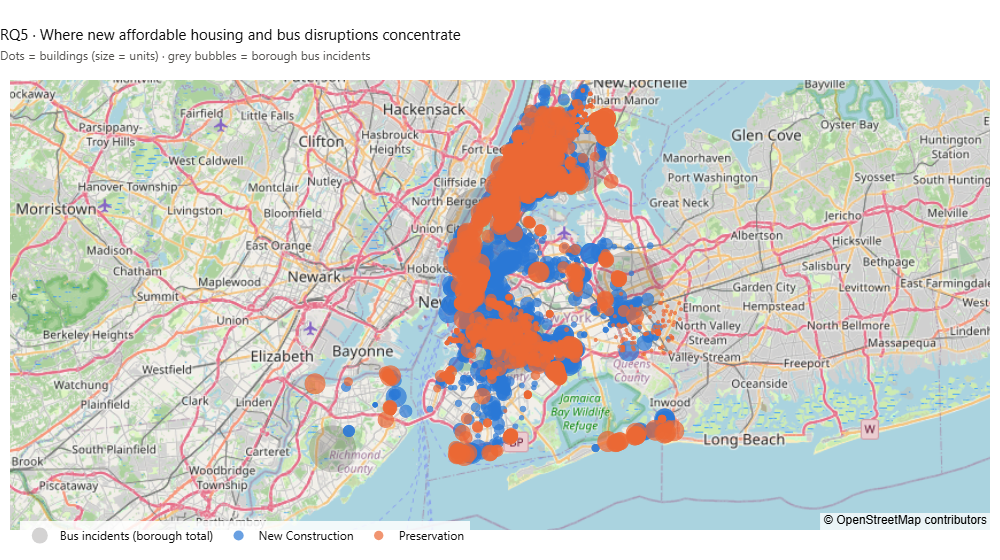

In [31]:
F.rq5_map(housing, yearly).show()

In [32]:
share = pd.DataFrame({'% of units': 100 * housing.groupby('borough')['total_units'].sum() / housing['total_units'].sum(),
                      '% of bus incidents': 100 * bus.groupby('borough').size() / len(bus)}).round(1)
share

,% of units,% of bus incidents
borough,,
BRONX,29.5,26.5
BROOKLYN,29.9,27.1
MANHATTAN,26.4,22.5
QUEENS,13.0,18.1
STATEN ISLAND,1.1,5.9


**Answer (Asser Ehab Khattab):** Broadly, yes. The Bronx, Brooklyn and Manhattan account for 29.5%, 29.9% and 26.4% of new affordable units, and for 26.5%, 27.1% and 22.5% of school-bus incidents. On the map, buildings concentrate in the Bronx, Upper Manhattan and central Brooklyn. Queens and Staten Island carry a larger share of incidents (18.1% and 5.9%) than of new units (13.0% and 1.1%), so disruptions there are not explained by new affordable housing. Because the bus data only gives the borough, the map cannot show whether disruptions happen near particular buildings.

**Caveat:** Bus bubbles sit at borough centres because the bus data has no finer location.

### RQ6 (Ali Sherif Elghayesh)
**Question:** In a borough's high new-construction years, is heavy traffic a larger share of delay reasons than in its low new-construction years?

**Chart:** Grouped bar per borough: heavy-traffic share in years above vs. below that borough's own median of new-construction units.

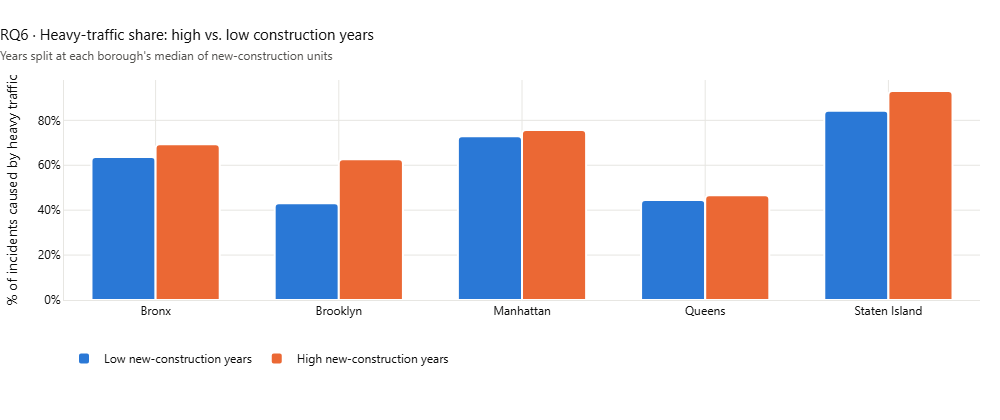

In [33]:
F.rq6_heavy_traffic_share(yearly).show()

**Answer (Ali Sherif Elghayesh):** In all five boroughs, heavy traffic was a larger share of delay causes in high new-construction years than in low ones: Brooklyn 43.1% to 62.7%, Staten Island 84.3% to 93.1%, the Bronx 63.7% to 69.4%, Manhattan 72.9% to 75.7% and Queens 44.5% to 46.6%. The gap is large only in Brooklyn and Staten Island. New construction grew over the decade and the heavy-traffic share also rose over time (the Bronx went from 59% in 2015-16 to 76% in 2024-25), so the passage of time alone could explain much of the pattern rather than construction itself.

**Caveat:** Each borough is compared only with itself, so differences in borough size do not drive the result.

### RQ7 (Ali Ahmed)
**Question:** Do borough-years that add more family-sized units (2+ bedrooms) see more students on board when a bus is disrupted?

**Chart:** Scatter of family-sized units vs. average students on the bus per incident, per borough × school year.

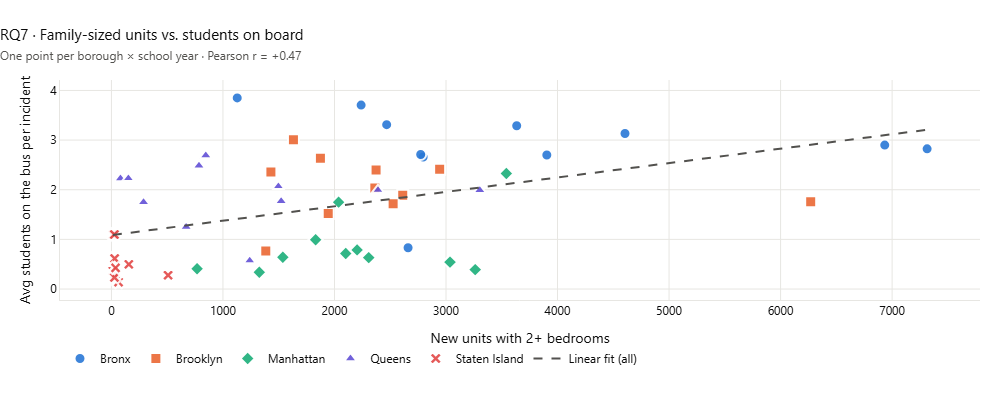

In [34]:
F.rq7_family_units_vs_students(yearly).show()

**Answer (Ali Ahmed):** Pooled across borough-years, more family-sized units goes with more students on board per incident (r = +0.47). Within boroughs, however, the relationship is mostly slightly negative (from -0.26 to -0.09 in the Bronx, Brooklyn, Queens and Staten Island), with Manhattan the only clear positive (+0.43). The pooled result therefore comes from differences between boroughs: Bronx buses average 2.9 students per incident against 0.9 in Manhattan and 0.5 in Staten Island. The student count is often 0 or blank, so these averages understate real loads. There is no evidence that adding family-sized units raises the number of students on disrupted buses.

**Caveat:** The student count is often recorded as 0 or left blank, which pulls averages down.

### RQ8 (Ahmed Rashad)
**Question:** Are Pre-K and school-age riders delayed for different lengths of time in high- vs. low-completion years?

**Chart:** Box plot of delay minutes by rider group, split into each borough's above- and below-median completion years.

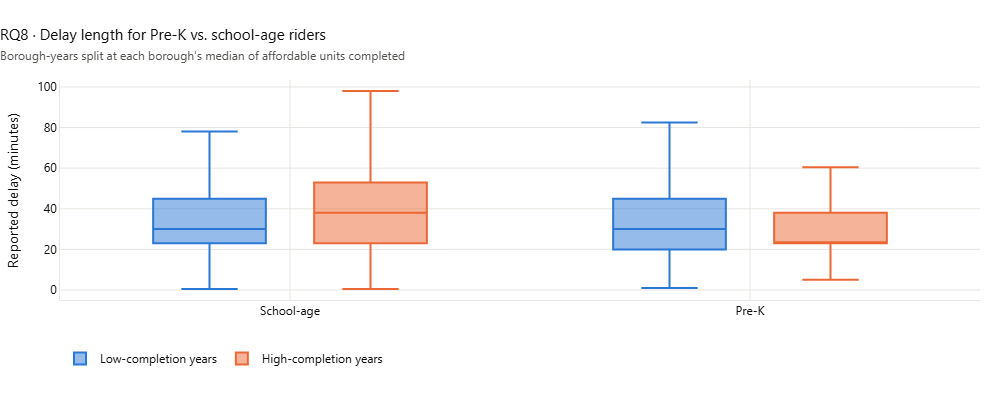

In [35]:
F.rq8_prek_delay_box(bus, yearly).show()

In [36]:
rider = np.where(bus['is_prek'], 'Pre-K', 'School-age')
bus.groupby(rider)['delay_minutes'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Pre-K,92815.0,33.2,20.3,1.0,23.0,23.0,38.0,180.0
School-age,647708.0,36.6,20.1,0.5,23.0,38.0,53.0,240.0


**Answer (Ahmed Rashad):** Overall, Pre-K delays are shorter than school-age delays (median 23 vs 38 min; mean 33.2 vs 36.6 min). Splitting each borough's school years at its median completions, school-age delays are longer in high-completion years (median 30 to 38 min, upper quartile 45 to 53 min), while Pre-K delays are *shorter* (median 30 to 23 min, upper quartile 45 to 38 min). The two rider groups move in opposite directions, which argues against a single housing-related effect on delays. High-completion years are also mostly the more recent ones, so the split partly reflects change over time.

**Caveat:** Delay minutes are self-reported by contractors and rounded.

## 8. Limitations

* **Correlation is not causation.** Housing completions and bus incidents both follow citywide trends (enrolment,
  contractor changes, the COVID-19 closure) that neither dataset records.
* **Borough-level only.** The bus data has no finer location, so a building and a delayed bus counted in the same
  borough may be far apart. Five boroughs × ~10 school years is a small sample for correlations.
* **Partial housing picture.** Only HPD-financed affordable units are included, not market-rate construction.
* **No denominator for buses.** The bus file gives no number of routes or riders, so incident counts are compared
  within each borough over time rather than across boroughs.
* **Self-reported delay text.** Unparseable or implausible delays were left blank, not imputed.

## 9. Who could use this

* **DOE Office of Pupil Transportation** — anticipate route capacity in boroughs with large upcoming completions.
* **HPD** — share the completion pipeline with OPT before buildings open.
* **Families and advocates** — evidence for requests about bus service near new affordable housing.

## 10. Prompts used and how AI was used

**What the team did:** We chose the two datasets (H2 + T5) and the deployment platform; Claude suggested candidate research questions, and each member selected and refined the two they own and can explain the code behind them. We ran the full pipeline on the real NYC Open Data downloads, solved the environment and data-download problems, published the repository, and deployed and tested the website on Render. Working through the results with Claude, we compared the findings against the notebook outputs. This caught two findings that misread the charts and a partial school year (2026-27) that inflated the correlations; we corrected the findings and excluded that year.

**How we used AI:** We used Claude (Anthropic) throughout the project. Claude produced the first draft of the code (`src/pipeline.py`, `src/figures.py`, `app.py`), the notebook's structure and explanatory text, the deployment files, and drafts of the findings and answers, which we then ran on the real data, tested, debugged and corrected with its help. Every step where we used AI is listed; repeated or long prompts are summarized.

| # | Step | Prompt (summarized where long) | What we did with the answer / what we learned |
|---|---|---|---|
| 1 | Project scaffolding | "i want to implement what these descriptions asked for in my data engineering and visualization course project for my uni" (brief and dataset catalog attached). Our choices: datasets H2 + T5, 4 members, Dash on Render, full project | Claude produced the first version of the pipeline, notebook, website and README; we ran it on the real data |
| 2 | Running locally | "how to run it exactly step by step", plus follow-ups on activating the virtual environment, `requirements.txt` not found, `jupyter` not recognized and a stalled pip download | Learned how virtual environments work, running tools with `python -m`, and that the unzipped project sits one folder deeper |
| 3 | Downloading the data | "when i press run all it redirects me to cell 8 9 10 11 and nothing happens"; "what is the size of the bus csv" | The API download hung on a slow connection, so we downloaded both CSVs in the browser into `data/raw/`, which the notebook reads as a cache |
| 4 | Notebook in VS Code | "why can't this notebook be run in my visual studio"; later the Plotly `nbformat` error | Learned how a notebook kernel is selected and why the kernel must restart after installing a package |
| 5 | Debugging a chart | "why is this one empty" (RQ6 at 0%); "i selected all boroughs and still" | We found the delay-reason filter was set to Accident, so 0% heavy traffic was correct; the heavy-traffic, breakdown and Pre-K matching was also made keyword-based |
| 6 | Checking the requirements | "did we make a dashboard like they requested?"; "this is correct right" (RQ1 showing one point) | Mapped each website requirement to a feature; learned a correlation needs at least three points |
| 7 | Findings | Shared screenshots of all eight charts | Claude drafted the website findings; comparing them with the notebook outputs showed two misreadings (RQ1 within-borough link, RQ8 delays), which we corrected |
| 8 | Deployment | GitHub errors ("remote origin already exists", push "rejected (fetch first)"), Render card verification, free-plan questions | Learned Git remotes and force-pushing to a new repository; deployed on Render's free plan |
| 9 | Final review | "check if it fits everything correctly from A-Z and fits all the requirements" | Claude tested the live site and repository: the notebook had been pushed without outputs, the app's memory use was reduced for the free plan, and a partial school year was found inflating the correlations; we re-ran and pushed |
| 10 | Team split and answers | Assigned the research questions by difficulty; "do all of these according to what you know" | Claude drafted the answer cells from the printed notebook outputs; each RQ owner checked their own answers before submission |

## 11. Dataset links

* Affordable Housing Production by Building — https://data.cityofnewyork.us/d/hg8x-zxpr
* Bus Breakdown and Delays — https://data.cityofnewyork.us/d/ez4e-fazm